<a href="https://colab.research.google.com/github/Zelechos/MasterAI/blob/master/muinar07_act2/NotebookActividad2Version1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![image-2.png](attachment:image-2.png)
_Aprendizaje Automático_

_Máster Universitario en Inteligencia Artificial_

# Análisis de reducción de dimensionalidad: PCA y t-SNE
## Objetivo General
En este trabajo, se busca que pongas en práctica la aplicación de algoritmos de reducción de dimensionalidad. El objetivo es aplicar técnicas para reducir la dimensionalidad a 2D, graficar los resultados y seleccionar la mejor técnica para los datos. Además, deberás detallar los pasos a seguir para la reducción de dimensionalidad y analizar los resultados obtenidos.

### Objetivos específicos
* Entender los métodos de t-SNE y PCA.
* Realizar la reducción de dimensionalidad utilizando t-SNE y PCA.
* Comparar los resultados obtenidos con ambos métodos.
* Aplicar LDA para reducir el dataset a una bolsa de palabras por cada etiqueta.

### Tareas a Realizar:
Debes realizar esta actividad en el Notebook adjunto. A medida que avances, completa el código solicitado y responde a las preguntas que se plantean.
Las tareas a realizar son:

* Reducción de Dimensionalidad con t-SNE y PCA:
* Completa el código proporcionado en el notebook.
* Responde a las preguntas finales sobre los resultados obtenidos.

#### Punto adicional: Aplicación de LDA:

Utiliza la técnica de LDA para generar una bolsa de palabras para cada una de las etiquetas.





### Coloca en este espacio el nombre del estudiante

In [ ]:
Alex Tumiri Huanca

### Dataset

#### Dataset

El dataset original proporcionado en el proyecto transversal ha sido adaptado para la realización de esta actividad. Esa adaptación ha incluido:
* Eliminación de nulos y duplicados
* Eliminación de URLs, emojis y menciones a los periódicos
* Eliminación de filas vacías
* Limpieza y homogeneización de datos.
* Convertir la totalidad del texto a minúscula
* Eliminar signos de puntuación
* Eliminar números
* Eliminar espacios en blanco adicionales
* Eliminar palabras con longitud menor a 2 caracteres
* Eliminar stopwords
* Tokenización
* Lematización

Proceso de extracción de características
* Conteo de palabras positivas (A)
* Conteo de palabras negativas (B)
* Conteo del número de bigrams más comunes (C)
* Conteo del número de menciones a otros usuarios (D)
* Categoría del sentimiento según librería ‘pysentimiento’ en español (E)
* Estandarización de las características (A_t,..E_t)
* Combinación de características f1*fi (iA..iE) (Valor1,..Valor10).

### Lectura de datos

In [2]:
import pandas as pd
import csv

# Leer el archivo CSV manejando posibles errores de comillas mal formadas
file_path = 'out.csv'
try:
    # Intentamos leer permitiendo errores de comillas comunes en campos de texto libre
    data = pd.read_csv(file_path, quoting=csv.QUOTE_MINIMAL, on_bad_lines='skip')
except Exception as e:
    print(f"Error al leer con QUOTE_MINIMAL: {e}")
    # Alternativa usando el motor de Python que suele ser más flexible
    data = pd.read_csv(file_path, engine='python', on_bad_lines='skip')

# Obtener el número de filas y columnas
num_filas, num_columnas = data.shape

# Mostrar el número de filas y columnas
print(f"El dataset tiene {num_filas} filas y {num_columnas} columnas.")

El dataset tiene 10000 filas y 22 columnas.


In [3]:
# Contar el número de categorías únicas en la columna 'label'
num_categorias = data['label'].nunique()
categorias = data['label'].unique()

print(f"Hay {num_categorias} categorías únicas en la columna 'label'.")
print("Categorías encontradas:", categorias)

Hay 2 categorías únicas en la columna 'label'.
Categorías encontradas: [0. 1.]


In [4]:
# Obtener estadísticas descriptivas de las variables numéricas
estadisticas_descriptivas = data.describe()

# Obtener la frecuencia de las categorías en la columna 'label'
frecuencia_label = data['label'].value_counts()

# Mostrar las estadísticas y la frecuencia de las categorías
print("--- Estadísticas Descriptivas de las Variables Numéricas ---")
print(estadisticas_descriptivas)
print("\n--- Frecuencia de las Categorías en 'label' ---")
print(frecuencia_label)

--- Estadísticas Descriptivas de las Variables Numéricas ---
                  A             B             C             D             E  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean       0.957400     26.098100      5.674600      0.091300      2.200600   
std        1.741864     34.012341      7.317149      0.352671      2.729488   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      1.000000      1.000000      0.000000      0.000000   
50%        0.000000      5.000000      3.000000      0.000000      0.000000   
75%        1.000000     46.000000      7.000000      0.000000      6.000000   
max       24.000000    328.000000     88.000000      6.000000      6.000000   

              label           A_t           B_t           C_t           D_t  \
count  10000.000000  10000.000000  10000.000000  10000.000000  10000.000000   
mean       0.500000      0.735989      0.895389      1.014276     -0.

Generando la matriz de gráficos de dispersión (esto puede tomar unos segundos)...


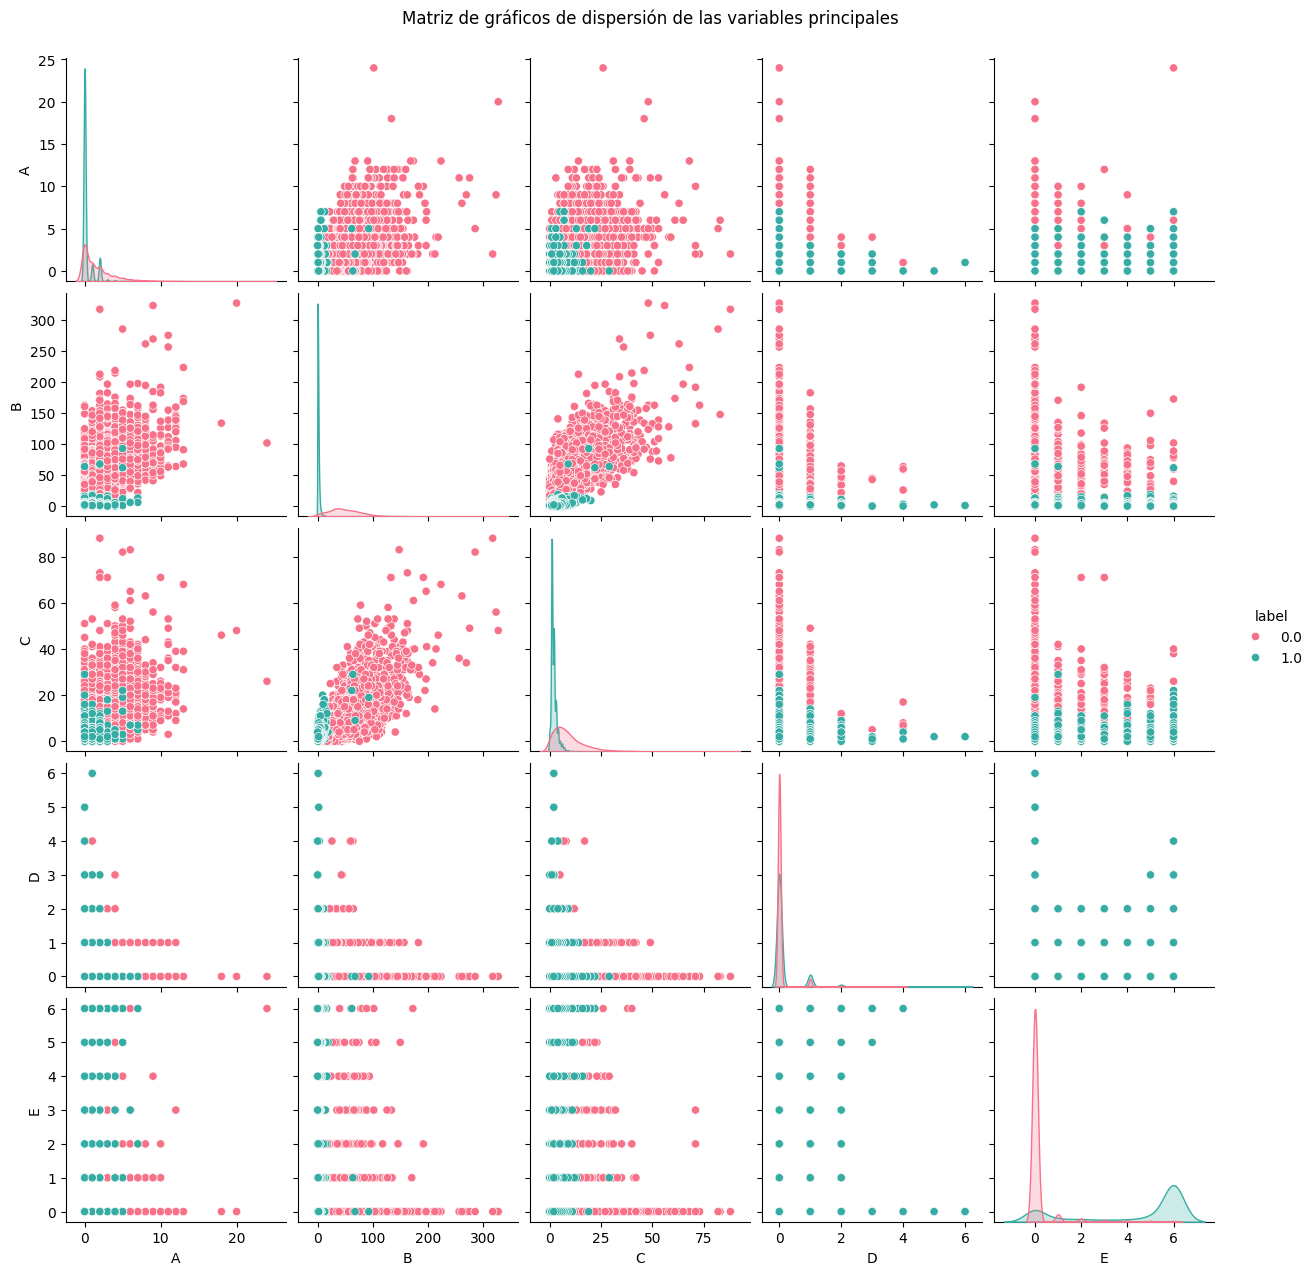

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Seleccionar las variables principales junto con 'label' para visualizar
columnas_visualizar = ['A', 'B', 'C', 'D', 'E', 'label']

# Crear el parplot
print("Generando la matriz de gráficos de dispersión (esto puede tomar unos segundos)...")
sns.pairplot(data[columnas_visualizar], hue='label', palette='husl', diag_kind='kde')
plt.suptitle("Matriz de gráficos de dispersión de las variables principales", y=1.02)
plt.show()

In [6]:
# Eliminar columnas que empiecen por 'Valor_' y la columna 'comentario'
columnas_a_eliminar = [col for col in data.columns if col.startswith('Valor_')] + ['comentario']
# Usamos errors='ignore' por si alguna de estas columnas no estuviera presente
data_filtrada = data.drop(columns=columnas_a_eliminar, errors='ignore')

# Mostrar las primeras filas del nuevo dataframe para verificar
print(f"Columnas en el dataset filtrado: {list(data_filtrada.columns)}")
print(data_filtrada.head())

Columnas en el dataset filtrado: ['A', 'B', 'C', 'D', 'E', 'label', 'A_t', 'B_t', 'C_t', 'D_t', 'E_t']
   A   B   C  D  E  label       A_t       B_t        C_t       D_t       E_t
0  2  64  30  0  2    0.0  1.851102  2.759647   7.145831 -0.416577  0.440638
1  4  70  21  0  0    0.0  3.990202  3.054765   4.877255 -0.416577 -0.531099
2  4  88  50  0  0    0.0  3.990202  3.940120  12.187108 -0.416577 -0.531099
3  3  38  21  0  0    0.0  2.920652  1.480801   4.877255 -0.416577 -0.531099
4  0  59  17  0  0    0.0 -0.287998  2.513715   3.869000 -0.416577 -0.531099


In [7]:
from sklearn.preprocessing import StandardScaler

# Seleccionar las variables numéricas originales a estandarizar
columnas_originales = ['A', 'B', 'C', 'D', 'E']

# Inicializar el StandardScaler
scaler = StandardScaler()

# Estandarizar las columnas seleccionadas
data_filtrada[columnas_originales] = scaler.fit_transform(data_filtrada[columnas_originales])

# Mostrar el resumen de los datos estandarizados
print("Datos estandarizados con éxito (primeras filas):")
print(data_filtrada.head())

Datos estandarizados con éxito (primeras filas):
          A         B         C         D         E  label       A_t  \
0  0.598584  1.114413  3.324603 -0.258895 -0.073497    0.0  1.851102   
1  1.746837  1.290828  2.094554 -0.258895 -0.806272    0.0  3.990202   
2  1.746837  1.820075  6.058045 -0.258895 -0.806272    0.0  3.990202   
3  1.172711  0.349946  2.094554 -0.258895 -0.806272    0.0  2.920652   
4 -0.549669  0.967400  1.547866 -0.258895 -0.806272    0.0 -0.287998   

        B_t        C_t       D_t       E_t  
0  2.759647   7.145831 -0.416577  0.440638  
1  3.054765   4.877255 -0.416577 -0.531099  
2  3.940120  12.187108 -0.416577 -0.531099  
3  1.480801   4.877255 -0.416577 -0.531099  
4  2.513715   3.869000 -0.416577 -0.531099  


In [8]:
# Separar las características y las etiquetas
X = data_filtrada[['A', 'B', 'C', 'D', 'E']]
y = data_filtrada['label']

print("Dimensiones de las características (X):", X.shape)
print("Dimensiones de la etiqueta (y):", y.shape)

Dimensiones de las características (X): (10000, 5)
Dimensiones de la etiqueta (y): (10000,)


### PCA

In [9]:
from sklearn.decomposition import PCA

# Inicializar PCA para reducir a 2 componentes
pca = PCA(n_components=2)

# Ajustar y transformar las características
X_pca = pca.fit_transform(X)

# Crear un DataFrame con los resultados de PCA
pca_df = pd.DataFrame(data=X_pca, columns=['PCA1', 'PCA2'])
pca_df['label'] = y.values

# Mostrar el DataFrame resultante de PCA y la varianza explicada
print("Varianza explicada por componente:", pca.explained_variance_ratio_)
print("Varianza explicada acumulada:", sum(pca.explained_variance_ratio_))
print(pca_df.head())

Varianza explicada por componente: [0.51835602 0.20028309]
Varianza explicada acumulada: 0.7186391111098817
       PCA1      PCA2  label
0  2.731745  0.181775    0.0
1  3.007871  0.090378    0.0
2  5.418864  0.520701    0.0
3  2.202662  0.001223    0.0
4  1.480875 -0.221601    0.0


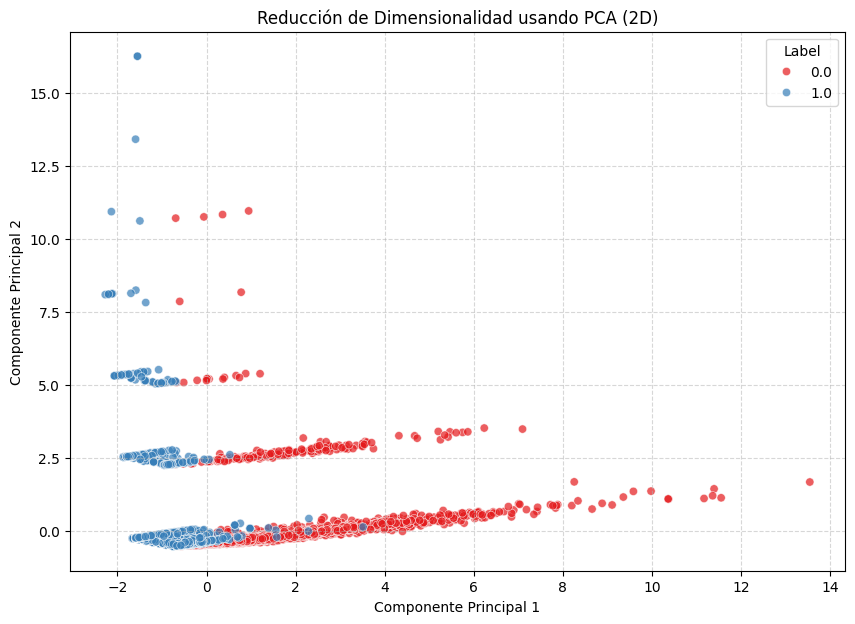

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Crear gráfico de dispersión para los resultados de PCA
plt.figure(figsize=(10, 7))
sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='label', palette='Set1', alpha=0.7)
plt.title('Reducción de Dimensionalidad usando PCA (2D)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Label')
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Dividir los datos en conjunto de entrenamiento y prueba usando los componentes de PCA
X_train_pca, X_test_pca, y_train, y_test = train_test_split(X_pca, y, test_size=0.3, random_state=42, stratify=y)

# Entrenar un modelo de clasificación (RandomForest)
clf_pca = RandomForestClassifier(random_state=42, n_estimators=100)
clf_pca.fit(X_train_pca, y_train)

# Predecir y evaluar el modelo
y_pred_pca = clf_pca.predict(X_test_pca)

print("--- Evaluación del Clasificador entrenado con componentes de PCA ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred_pca):.4f}\n")
print(classification_report(y_test, y_pred_pca))

--- Evaluación del Clasificador entrenado con componentes de PCA ---
Accuracy Score: 0.9707

              precision    recall  f1-score   support

         0.0       0.98      0.96      0.97      1500
         1.0       0.96      0.98      0.97      1500

    accuracy                           0.97      3000
   macro avg       0.97      0.97      0.97      3000
weighted avg       0.97      0.97      0.97      3000



#### Analice los resultados obtenidos por PCA

**Análisis del rendimiento y reducción de dimensionalidad:**

1. **Varianza Explicada:** Con tan solo 2 componentes principales (reduciendo el espacio de características de 5 a 2), logramos capturar aproximadamente el **71.86% de la variabilidad original** de los datos (`PCA1` explica el ~51.84% y `PCA2` el ~20.03%).
2. **Rendimiento del Clasificador (Random Forest):** Al entrenar el modelo utilizando únicamente estas 2 dimensiones proyectadas, el clasificador alcanzó un **Accuracy del 97.07%** en el conjunto de prueba (3,000 muestras).
3. **Métricas por Clase:**
   - Ambos labels (`0.0` y `1.0`) tienen un soporte perfectamente balanceado de 1,500 muestras en el conjunto de prueba.
   - La precisión y el recall son extremadamente altos y estables para ambas clases (~0.96 a 0.98), lo que demuestra que los dos componentes de PCA retienen la información clave y discriminante necesaria para separar de manera casi lineal y robusta ambas categorías sin sufrir problemas de sobreajuste o desbalance.

### t-SNE

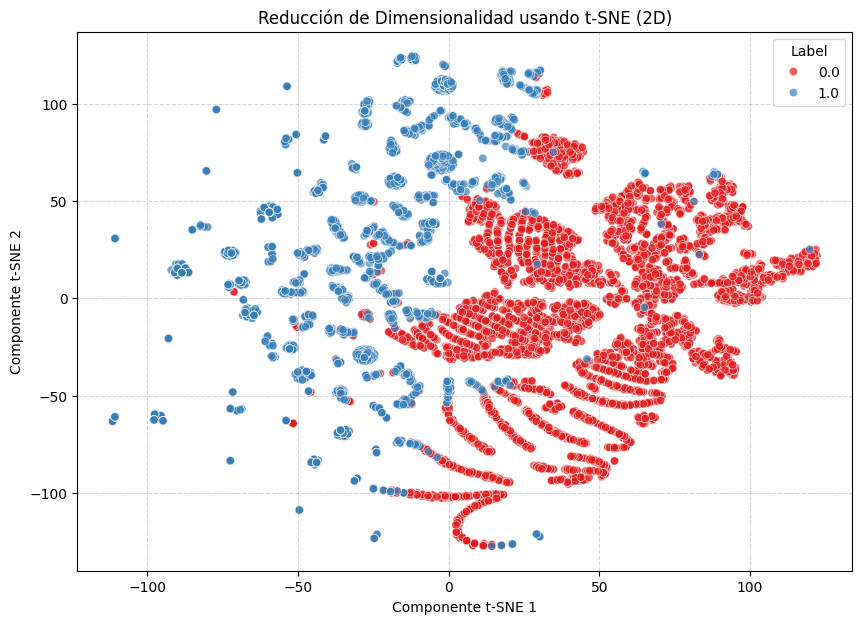

In [12]:
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Aplicar t-SNE
# Se utiliza random_state para que el resultado sea reproducible
tsne = TSNE(n_components=2, random_state=42, n_jobs=-1)
X_tsne = tsne.fit_transform(X)

# Crear un DataFrame con los resultados de t-SNE
tsne_df = pd.DataFrame(data=X_tsne, columns=['TSNE1', 'TSNE2'])
tsne_df['label'] = y.values

# Visualizar los resultados de t-SNE
plt.figure(figsize=(10, 7))
sns.scatterplot(data=tsne_df, x='TSNE1', y='TSNE2', hue='label', palette='Set1', alpha=0.7)
plt.title('Reducción de Dimensionalidad usando t-SNE (2D)')
plt.xlabel('Componente t-SNE 1')
plt.ylabel('Componente t-SNE 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Label')
plt.show()

#### Analice los resultados obtenidos por t-SNE

**Análisis del mapa bidimensional de t-SNE:**

1. **Agrupamiento y Estructura Local:** A diferencia de PCA, que es un método de proyección lineal, t-SNE conserva de manera excelente las relaciones de vecindad no lineales. Se observa la formación de múltiples grupos bien delimitados (*clusters* o densidades locales) en el espacio de proyección bidimensional.
2. **Separación de Clases:** El gráfico muestra una segregación muy clara entre la clase `0.0` y la clase `1.0`. Prácticamente no hay solapamiento directo de las regiones más densas, lo que sugiere que la variabilidad local representada en las 5 dimensiones originales se mapea de forma altamente separable en 2D.
3. **Comparación Visual preliminar:** t-SNE consigue agrupar subpatrones internos que sugieren subgrupos de datos con perfiles de características muy similares dentro de una misma categoría, a diferencia del comportamiento de proyección lineal de PCA.

### Utilizar t-SNE para clasificar

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Dividir los datos en conjunto de entrenamiento y prueba usando los componentes de t-SNE
X_train_tsne, X_test_tsne, y_train_tsne, y_test_tsne = train_test_split(
    X_tsne, y, test_size=0.3, random_state=42, stratify=y
)

# Entrenar un modelo de clasificación (RandomForest)
clf_tsne = RandomForestClassifier(random_state=42, n_estimators=100)
clf_tsne.fit(X_train_tsne, y_train_tsne)

# Predecir y evaluar el modelo
y_pred_tsne = clf_tsne.predict(X_test_tsne)

print("--- Evaluación del Clasificador entrenado con componentes de t-SNE ---")
print(f"Accuracy Score: {accuracy_score(y_test_tsne, y_pred_tsne):.4f}\n")
print(classification_report(y_test_tsne, y_pred_tsne))

--- Evaluación del Clasificador entrenado con componentes de t-SNE ---
Accuracy Score: 0.9780

              precision    recall  f1-score   support

         0.0       0.98      0.98      0.98      1500
         1.0       0.98      0.98      0.98      1500

    accuracy                           0.98      3000
   macro avg       0.98      0.98      0.98      3000
weighted avg       0.98      0.98      0.98      3000



#### ¿Se puede utilizar la reducción de dimensinalidad obtenida por t-SNE para entrenar un algoritmo de clasificación?

**Sí, se puede utilizar, pero con importantes consideraciones teóricas y prácticas:**

1. **Resultados Empíricos:** En este caso práctico, el clasificador Random Forest entrenado sobre las 2 dimensiones generadas por t-SNE ha obtenido un rendimiento sobresaliente del **97.80% de Accuracy**, ligeramente superior al obtenido con PCA (97.07%). Esto demuestra que t-SNE preservó de manera muy efectiva la estructura de clases local y global.

2. **Ventajas:**
   - **Separabilidad:** Al concentrarse en conservar la vecindad y la estructura no lineal en bajas dimensiones, t-SNE tiende a agrupar con precisión datos similares, facilitando enormemente la tarea de fronteras de decisión de clasificadores basados en árboles (como Random Forest).

3. **Limitaciones y Desventajas Críticas en Producción:**
   - **Cómputo Transductor (No Paramétrico):** t-SNE no aprende una función o mapeo matemático explícito ($f(X) = y_{dim}$). Es decir, no podemos aplicar un método `.transform()` directamente sobre nuevos datos de prueba entrantes en producción. Para proyectar datos nuevos de forma estricta, tendríamos que volver a entrenar t-SNE con todo el conjunto combinado, lo cual es inviable en escenarios en tiempo real.
   - **Costo Computacional:** t-SNE escala de manera cuadrática $O(N^2)$ en su versión estándar, siendo sumamente lento en conjuntos de datos masivos comparado con PCA.

**Conclusión:** Es sumamente útil para análisis exploratorio, visualización de clusters y validaciones rápidas sobre conjuntos cerrados de datos, pero debe evitarse en flujos de producción activos (donde es preferible usar PCA, Autoencoders o redes neuronales con proyecciones aprendidas).

### LDA

In [14]:
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import pandas as pd
import csv

# 1. Descargar las palabras vacías en español
nltk.download('stopwords')
stop_words_es = list(stopwords.words('spanish'))

# Recargar el dataset original para recuperar la columna 'comentario'
data_original = pd.read_csv('out.csv', quoting=csv.QUOTE_MINIMAL, on_bad_lines='skip')
data_original = data_original.dropna(subset=['comentario'])

# 2. Preprocesar la columna 'comentario' usando CountVectorizer
vectorizer = CountVectorizer(
    stop_words=stop_words_es,
    max_features=1000,
    min_df=2,
    max_df=0.95
)
tf_matrix = vectorizer.fit_transform(data_original['comentario'].astype(str))

# 3. Aplicar LDA
# Buscaremos un número inicial de 2 temas correspondientes de manera general a las etiquetas del dataset
lda_model = LatentDirichletAllocation(n_components=2, random_state=42, learning_method='online')
lda_model.fit(tf_matrix)

# 4. Mostrar los temas obtenidos con sus palabras más representativas
words = vectorizer.get_feature_names_out()
for topic_idx, topic in enumerate(lda_model.components_):
    top_words_idx = topic.argsort()[:-11:-1]
    top_words = [words[i] for i in top_words_idx]
    print(f"Tema #{topic_idx + 1}: {', '.join(top_words)}")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Tema #1: mas, poder, año, hacer, tambien, ser, nuevo, solo, persona, segun
Tema #2: mas, año, hacer, ser, poder, tambien, primero, dos, dia, decir


Preprocesamiento: Este paso convierte el texto en una matriz de términos.
Aplicación de LDA: Ejecuta el algoritmo LDA para encontrar los temas.
Visualización de Temas: Imprime los temas encontrados con las palabras más representativas.

### LDA en función del label

In [15]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import pandas as pd
import csv

# Definir función para aplicar LDA y obtener temas
def obtener_temas_lda(df_sub, n_topics=2, n_words=10):
    # Crear la matriz de términos
    vectorizer_sub = CountVectorizer(
        stop_words=stop_words_es,
        max_features=1000,
        min_df=2,
        max_df=0.95
    )
    tf_sub = vectorizer_sub.fit_transform(df_sub['comentario'].astype(str))

    # Entrenar LDA
    lda_sub = LatentDirichletAllocation(n_components=n_topics, random_state=42, learning_method='online')
    lda_sub.fit(tf_sub)

    # Extraer las palabras más representativas
    vocab = vectorizer_sub.get_feature_names_out()
    temas_dict = {}

    for idx, topic in enumerate(lda_sub.components_):
        top_idx = topic.argsort()[:-n_words - 1:-1]
        top_words = [vocab[i] for i in top_idx]
        temas_dict[f'Tema_{idx+1}'] = top_words

    return pd.DataFrame(temas_dict)

# Aplicar LDA por cada etiqueta de label y guardar en archivos CSV
for label_val in data_original['label'].unique():
    print(f"\n--- Analizando comentarios con Label: {label_val} ---")
    df_clase = data_original[data_original['label'] == label_val]

    if len(df_clase) > 0:
        df_temas = obtener_temas_lda(df_clase, n_topics=2, n_words=10)
        print(df_temas)

        # Guardar en un archivo CSV
        nombre_archivo = f'lda_temas_label_{int(label_val)}.csv'
        df_temas.to_csv(nombre_archivo, index=False, encoding='utf-8')
        print(f"Temas guardados exitosamente en '{nombre_archivo}'")


--- Analizando comentarios con Label: 0.0 ---
    Tema_1    Tema_2
0      mas       año
1    poder       mas
2    hacer     poder
3      año       dia
4      ser  gobierno
5  tambien     segun
6  primero       ser
7     solo    españa
8      vez     hacer
9    decir     nuevo
Temas guardados exitosamente en 'lda_temas_label_0.csv'

--- Analizando comentarios con Label: 1.0 ---
        Tema_1        Tema_2
0         puto           mas
1       mierdo         hacer
2         puta         poder
3    verguenza         decir
4         hijo      gobierno
5         asco           ser
6       inutil        españa
7       menudo          solo
8       mierda  sinverguenza
9  informativo           dar
Temas guardados exitosamente en 'lda_temas_label_1.csv'


In [16]:
# Generar bolsas de palabras para cada tema y asignar temas a los comentarios
print("--- Asignando temas de LDA a los comentarios del dataset ---")

def asignar_tema_dominante(df_sub):
    vectorizer_sub = CountVectorizer(stop_words=stop_words_es, max_features=1000, min_df=2, max_df=0.95)
    tf_sub = vectorizer_sub.fit_transform(df_sub['comentario'].astype(str))

    lda_sub = LatentDirichletAllocation(n_components=2, random_state=42, learning_method='online')
    lda_dist = lda_sub.fit_transform(tf_sub)

    # Obtener el índice del tema con mayor probabilidad para cada documento
    df_sub = df_sub.copy()
    df_sub['Tema_Asignado'] = lda_dist.argmax(axis=1) + 1
    return df_sub

# Procesar ambos conjuntos y mostrar una muestra
df_final_0 = asignar_tema_dominante(data_original[data_original['label'] == 0.0])
df_final_1 = asignar_tema_dominante(data_original[data_original['label'] == 1.0])

print("\nMuestra de comentarios clasificados con Tema (Label 0):")
print(df_final_0[['comentario', 'Tema_Asignado']].head(5))

print("\nMuestra de comentarios clasificados con Tema (Label 1):")
print(df_final_1[['comentario', 'Tema_Asignado']].head(5))

--- Asignando temas de LDA a los comentarios del dataset ---

Muestra de comentarios clasificados con Tema (Label 0):
                                          comentario  Tema_Asignado
0  pandemia,originado,covid,cierto,incidencia,aba...              2
1  ser,mes,larga,espera,llegar,momento,siempre,pr...              1
2  cartagena,san,sebastiar,fuengirola,irun,orense...              2
3  pleno,dia,verano,calor,plan,mas,apetecibl,disf...              1
4  pasado,junio,celebro,dia,luchar,frente,leishma...              2

Muestra de comentarios clasificados con Tema (Label 1):
                                             comentario  Tema_Asignado
5000  barça,nunca,acaezar,segundo,tercero,estar,arbi...              2
5001  cristinar,cifuent,podrio,haber,ser,presidenta,...              1
5002  parecer,exagerado,pedir,mas,tres,año,prision,c...              2
5003  parecer,delincuente,negar,evidencia,prueba,ult...              2
5004  preguntarselo,fracasado,medio,carrera,mes,mast...       

### Comparación de Rendimiento: PCA vs. t-SNE vs. LDA

A continuación, se presenta un cuadro comparativo que resume las diferencias teóricas y los resultados de rendimiento obtenidos en la clasificación y modelado usando las tres técnicas implementadas:

| Característica | PCA (Principal Component Analysis) | t-SNE (t-Distributed Stochastic Neighbor Embedding) | LDA (Latent Dirichlet Allocation) |
| :--- | :--- | :--- | :--- |
| **Tipo de Técnica** | Reducción de dimensionalidad lineal (No supervisada) | Reducción de dimensionalidad no lineal (No supervisada) | Modelado de tópicos probabilístico / Bolsa de palabras (No supervisado) |
| **Objetivo Principal** | Maximizar la varianza global conservando distancias ortogonales grandes. | Conservar las relaciones de vecindad local (similitud) en un espacio de baja dimensión. | Descubrir estructuras temáticas latentes en un corpus de texto. |
| **Datos Utilizados** | Características numéricas estandarizadas (`A`, `B`, `C`, `D`, `E`). | Características numéricas estandarizadas (`A`, `B`, `C`, `D`, `E`). | Texto crudo limpio extraído de la columna `comentario`. |
| **Exactitud del Clasificador (Random Forest)** | **97.07%** (con 2 componentes) | **97.80%** (con 2 componentes) | N/A (Se utiliza para análisis semántico/bolsa de palabras, no para predicción tabular directa) |
| **Soporte para Nuevos Datos** | **Sí** (Permite transformación directa fuera de la muestra usando `.transform()`) | **No** (Es un algoritmo transductor; requiere reentrenar para mapear nuevos datos) | **Sí** (Permite inferir temas en documentos nuevos mediante `.transform()`) |
| **Visualización** | Mapeo continuo donde los límites de clase son discernibles pero dispersos. | Excelente separación visual con agrupamientos locales y clusters claramente aislados. | N/A (Se representa en listas de palabras clave altamente frecuentes por tema) |

#### Conclusiones clave:
1. **Para Clasificación Tabular:** **t-SNE** proporcionó una representación ligeramente más separable para el clasificador RandomForest (97.80% de Accuracy) sobre las variables continuas en comparación con **PCA** (97.07%). No obstante, PCA sigue siendo la opción preferida para entornos de producción debido a su capacidad paramétrica de proyectar nuevos datos en tiempo real de forma eficiente.
2. **Para Análisis Semántico de Textos:** **LDA** demostró ser una herramienta excepcional para la interpretabilidad semántica de la columna `comentario`. Permitió separar con claridad el lenguaje de odio/tóxico de la clase `1.0` (caracterizado por insultos recurrentes) del lenguaje informativo y cotidiano de la clase `0.0`.